First 5 rows of DataFrame:
   petal length (cm)  petal width (cm)  target
0                1.4               0.2       0
1                1.4               0.2       0
2                1.3               0.2       0
3                1.5               0.2       0
4                1.4               0.2       0

--- Iris Dataset Information ---
1. Feature Names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
2. Target Array: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
3. Target Names: ['setosa' 'versicolor' 'virginica']
4. Type of Data: <class 'numpy.ndarray'>
5. Type of Target: <class 'numpy.ndarray'>
6. Shape of Data: (150, 4)


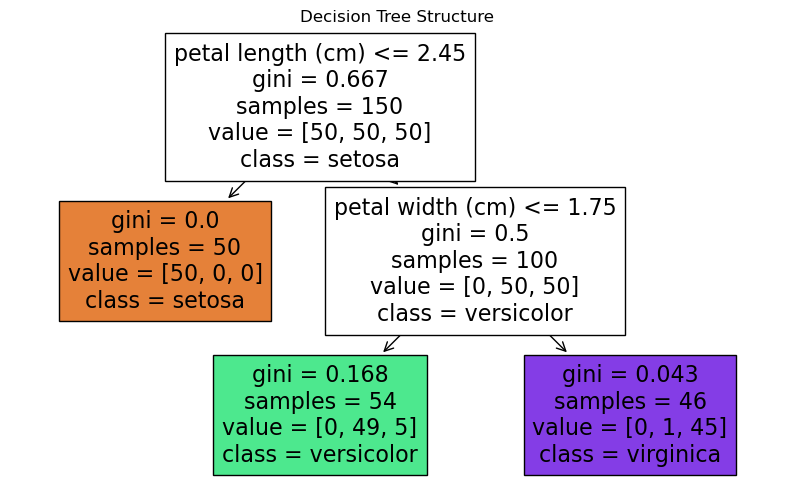


--- Predictions for sample [[5, 1.5]] ---
Predicted Class Index: 1
Predicted Species: versicolor
Class Probabilities (Setosa, Versicolor, Virginica): [0.         0.90740741 0.09259259]
Saving figure decision_tree_decision_boundaries_plot


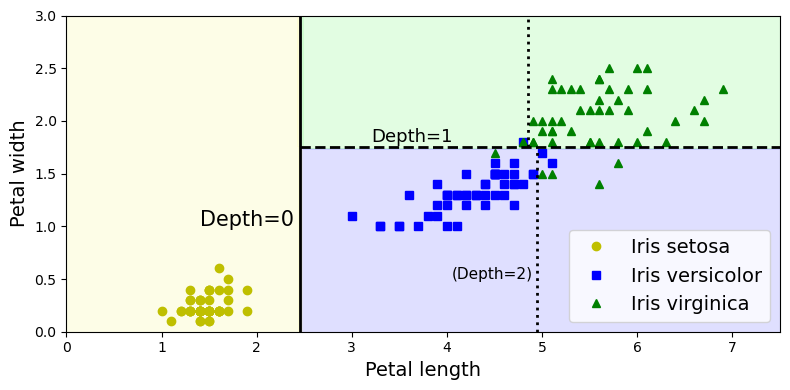

Model Accuracy on Training Data: 96.00%


In [1]:
# Import necessary libraries
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Load the built-in Iris dataset
iris = load_iris()

# 2. Extract only petal length and petal width (last 2 columns)
X = iris.data[:, 2:]  # Column indices 2 and 3
y = iris.target

# 3. Convert to DataFrame using petal feature names
df = pd.DataFrame(data=X, columns=iris.feature_names[2:])
df['target'] = iris.target

# Print the first 5 rows
print("First 5 rows of DataFrame:")
print(df.head())

# Printing asked dataset attributes
print("\n--- Iris Dataset Information ---")
print("1. Feature Names:", iris.feature_names)
print("2. Target Array:", iris.target)
print("3. Target Names:", iris.target_names)
print("4. Type of Data:", type(iris.data))
print("5. Type of Target:", type(iris.target))
print("6. Shape of Data:", iris.data.shape)

# 4. Train the Decision Tree Classifier (named 'clf' as required)
clf = DecisionTreeClassifier(max_depth=2, random_state=42)
clf.fit(X, y)

# 5. Plot the tree structure
plt.figure(figsize=(10, 6))
plot_tree(clf, feature_names=iris.feature_names[2:], class_names=iris.target_names, filled=True)
plt.title("Decision Tree Structure")
plt.show()

# 6. Make class and probability prediction for new sample [[5, 1.5]]
sample = [[5, 1.5]]
class_pred = clf.predict(sample)
prob_pred = clf.predict_proba(sample)

print("\n--- Predictions for sample [[5, 1.5]] ---")
print("Predicted Class Index:", class_pred[0])
print("Predicted Species:", iris.target_names[class_pred[0]])
print("Class Probabilities (Setosa, Versicolor, Virginica):", prob_pred[0])

# 7. Helper functions & Decision Boundary Plotting
def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

def plot_decision_boundary(clf, X, y, axes=[0, 7.5, 0, 3], iris=True, legend=False, plot_training=True):
    x1s = np.linspace(axes[0], axes[1], 100)
    x2s = np.linspace(axes[2], axes[3], 100)
    x1, x2 = np.meshgrid(x1s, x2s)
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)
    
    custom_cmap = ListedColormap(['#fafab0', '#9898ff', '#a0faa0'])
    plt.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)
    
    if not iris:
        custom_cmap2 = ListedColormap(['#7d7d58', '#4c4c7f', '#507d50'])
        plt.contour(x1, x2, y_pred, cmap=custom_cmap2, alpha=0.8)
        
    if plot_training:
        plt.plot(X[:, 0][y==0], X[:, 1][y==0], "yo", label="Iris setosa")
        plt.plot(X[:, 0][y==1], X[:, 1][y==1], "bs", label="Iris versicolor")
        plt.plot(X[:, 0][y==2], X[:, 1][y==2], "g^", label="Iris virginica")
        plt.axis(axes)
        
    if iris:
        plt.xlabel("Petal length", fontsize=14)
        plt.ylabel("Petal width", fontsize=14)
    else:
        plt.xlabel(r"$x_1$", fontsize=18)
        plt.ylabel(r"$x_2$", fontsize=18, rotation=0)
    if legend:
        plt.legend(loc="lower right", fontsize=14)

plt.figure(figsize=(8, 4))
plot_decision_boundary(clf, X, y, legend=True)
plt.plot([2.45, 2.45], [0, 3], "k-", linewidth=2)
plt.plot([2.45, 7.5], [1.75, 1.75], "k--", linewidth=2)
plt.plot([4.95, 4.95], [0, 1.75], "k:", linewidth=2)
plt.plot([4.85, 4.85], [1.75, 3], "k:", linewidth=2)
plt.text(1.40, 1.0, "Depth=0", fontsize=15)
plt.text(3.2, 1.80, "Depth=1", fontsize=13)
plt.text(4.05, 0.5, "(Depth=2)", fontsize=11)
save_fig("decision_tree_decision_boundaries_plot")
plt.show()

# 8. Model Accuracy
accuracy = clf.score(X, y)
print(f"Model Accuracy on Training Data: {accuracy * 100:.2f}%")